# Localización de los emisores del RETC para usarlos como SO (sources) en Aermap

In [8]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

import geopandas as gpd

from pyproj import Transformer

current_directory = os.getcwd()
print("Current working directory:", current_directory)

Current working directory: /Users/gabrielevangelista/thesis-cdmx-air/03-analysis/cleaning_retc


In [ ]:
df_sources= pd.read_csv('../../02-data/processed/sources_loc/retc_15_19_est_min_clean.csv')
df_sources

,NRA,COORDENADA_UTM_X,COORDENADA_UTM_Y
0,AAL1512102650,478326.4580,2.171540e+06
1,AAL7Q1503321,494746.4971,2.162444e+06
2,AAL7Q1510911,483998.7598,2.171968e+06
3,AAM1503900040,505305.7470,2.137438e+06
4,AAZEE0900211,481717.0060,2.154351e+06
...,...,...,...
716,YIN3K0901711,489383.1745,2.149112e+06
717,YOP0901000433,478702.1226,2.138869e+06
718,ZDE5J1508111,501362.4573,2.178539e+06
719,ZMO0900700072,491638.2866,2.143070e+06


In [ ]:
# convertir mi en mi df_sources, quiero convertir mis columnas 1 y 2, de coordenadas utm x y a lat long a UTM Zona 14N (EPSG:32614). 


transformer_inv = Transformer.from_crs("EPSG:32614", "EPSG:4326", always_xy=True)

x = df_sources.iloc[:, 1].astype(float)
y = df_sources.iloc[:, 2].astype(float)

lon, lat = transformer_inv.transform(x.values, y.values)

df_sources['lon'] = lon
df_sources['lat'] = lat

df_sources


,NRA,COORDENADA_UTM_X,COORDENADA_UTM_Y,lon,lat
0,AAL1512102650,478326.4580,2.171540e+06,-99.206726,19.638940
1,AAL7Q1503321,494746.4971,2.162444e+06,-99.050084,19.556850
2,AAL7Q1510911,483998.7598,2.171968e+06,-99.152626,19.642858
3,AAM1503900040,505305.7470,2.137438e+06,-98.949488,19.330862
4,AAZEE0900211,481717.0060,2.154351e+06,-99.174220,19.483631
...,...,...,...,...,...
716,YIN3K0901711,489383.1745,2.149112e+06,-99.101139,19.436339
717,YOP0901000433,478702.1226,2.138869e+06,-99.202775,19.343684
718,ZDE5J1508111,501362.4573,2.178539e+06,-98.987000,19.702304
719,ZMO0900700072,491638.2866,2.143070e+06,-99.079630,19.381746


In [6]:
df_retc= df_sources

## Proyectar en mapa de ZMVM

In [15]:
# 1. Crear el GeoDataFrame en WGS84 (EPSG:4326) y verificar proyección UTM 14N (EPSG:32614)
gdf_retc = gpd.GeoDataFrame(
    df_retc, 
    geometry=gpd.points_from_xy(df_retc['lon'], df_retc['lat']),
    crs="EPSG:4326"
)

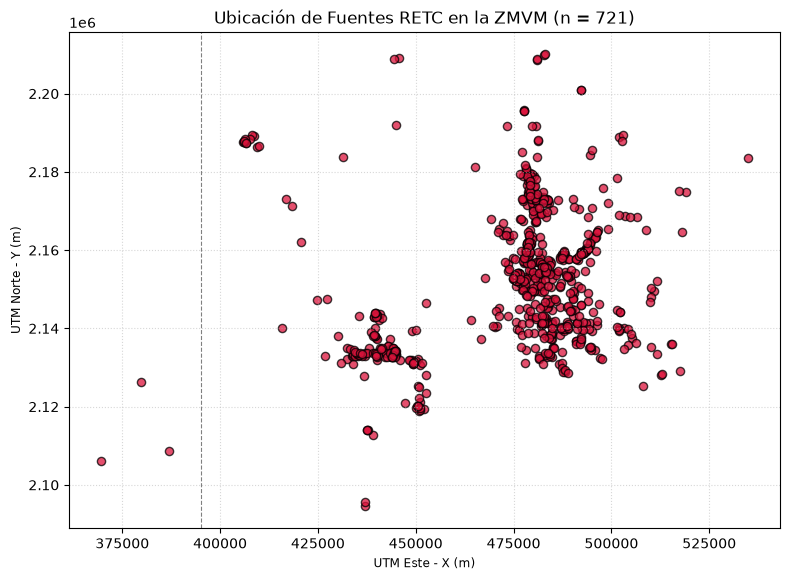

Fuentes fuera de los DEMs SRTM (n19_w099 / n19_w100): 5


,NRA,COORDENADA_UTM_X,COORDENADA_UTM_Y,lon,lat,geometry
130,CFEH71511011,379740.8163,2.126262e+06,-100.144102,19.226296,POINT (-100.1441 19.2263)
288,GMI1508600015,386964.1379,2.108610e+06,-100.074358,19.067207,POINT (-100.07436 19.06721)
413,LOMBJ1508811,437045.9126,2.094739e+06,-99.597931,18.944013,POINT (-99.59793 18.94401)
468,MTI141511611,369658.3956,2.106069e+06,-100.238645,19.043219,POINT (-100.23865 19.04322)
561,PRO5T1508811,437080.6926,2.095748e+06,-99.597633,18.953132,POINT (-99.59763 18.95313)


In [16]:
# Alternativa estática en UTM Zona 14N (metros) con límites de validación de la ZMVM
gdf_utm = gdf_retc.to_crs("EPSG:32614")

fig, ax = plt.subplots(figsize=(8, 8))
gdf_utm.plot(ax=ax, color='crimson', edgecolor='black', markersize=35, alpha=0.75)

# Caja envolvente aproximada de la ZMVM y cobertura de tus DEMs (n19_w099 y n19_w100)
ax.axvline(x=395000, color='gray', linestyle='--', linewidth=0.8, label='Límite DEM (100°W / 99°W)')
ax.set_title(f"Ubicación de Fuentes RETC en la ZMVM (n = {len(gdf_utm)})", fontsize=12)
ax.set_xlabel("UTM Este - X (m)")
ax.set_ylabel("UTM Norte - Y (m)")
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

# Verificación rápida: detectar puntos fuera del rango de tus 2 archivos .tif (19°N-20°N, 98°W-100°W)
fuera_dem = gdf_retc[
    (gdf_retc['lat'] < 19.0) | (gdf_retc['lat'] > 20.0) | 
    (gdf_retc['lon'] < -100.0) | (gdf_retc['lon'] > -98.0)
]
print(f"Fuentes fuera de los DEMs SRTM (n19_w099 / n19_w100): {len(fuera_dem)}")
if not fuera_dem.empty:
    display(fuera_dem)


In [12]:
# Filtrar solo las instalaciones dentro de la cobertura de los DEMs de la cuenca (19°N-20°N, 100°W-98°W)
gdf_zmvm = gdf_retc[
    (gdf_retc['lat'] >= 19.005) & (gdf_retc['lat'] <= 19.995) & 
    (gdf_retc['lon'] >= -99.995) & (gdf_retc['lon'] <= -98.005)
].copy()

print(f"Fuentes originales: {len(gdf_retc)} | Fuentes válidas en dominio ZMVM: {len(gdf_zmvm)}")


Fuentes originales: 721 | Fuentes válidas en dominio ZMVM: 716


In [13]:
# 1. Asegurar coordenadas UTM Zona 14N (EPSG:32614) consistentes calculadas por PROJ/GeoPandas
gdf_zmvm_utm = gdf_zmvm.to_crs("EPSG:32614")
gdf_zmvm['X_UTM'] = gdf_zmvm_utm.geometry.x.round(2)
gdf_zmvm['Y_UTM'] = gdf_zmvm_utm.geometry.y.round(2)

# 2. Crear ID corto compatible con Fortran (S0001, S0002...)
gdf_zmvm = gdf_zmvm.reset_index(drop=True)
gdf_zmvm['SRCID'] = [f"S{i+1:04d}" for i in range(len(gdf_zmvm))]

# 3. Guardar catálogo maestro (vínculo NRA <-> SRCID) para cuando armemos las emisiones por año
gdf_zmvm[['SRCID', 'NRA', 'X_UTM', 'Y_UTM', 'lon', 'lat']].to_csv(
    'catalogo_fuentes_retc_zmvm.csv', index=False
)

# 4. Escribir el bloque SO para AERMAP
with open('bloque_so_aermap.txt', 'w') as f:
    f.write("SO STARTING\n")
    for _, row in gdf_zmvm.iterrows():
        f.write(f"   LOCATION  {row['SRCID']:<8s}  POINT  {row['X_UTM']:11.2f}  {row['Y_UTM']:11.2f}\n")
    f.write("SO FINISHED\n")

print(f"Listo: {len(gdf_zmvm)} fuentes exportadas a 'bloque_so_aermap.txt' y 'catalogo_fuentes_retc_zmvm.csv'")


Listo: 716 fuentes exportadas a 'bloque_so_aermap.txt' y 'catalogo_fuentes_retc_zmvm.csv'
